# Notebook 03: Conversion Prediction

## AI Revenue Optimization & Conversion Intelligence System for Nattoguard

This notebook focuses on building machine learning models to predict whether a customer session is likely to generate revenue.

The main target variable is `Revenue`, where:

- `True` means the session resulted in a purchase.
- `False` means the session did not result in a purchase.

The goal is to create a predictive model that estimates customer purchase probability. These probabilities will later be used to create customer intent groups and support AI-driven marketing actions, LLM-generated messages, and chatbot workflows.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = Path("../data/processed/online_shoppers_cleaned.csv")
FIGURES_PATH = Path("../outputs/figures")
MODEL_RESULTS_PATH = Path("../outputs/model_results")
CHATBOT_INPUTS_PATH = Path("../outputs/chatbot_inputs")
SLIDE_ASSETS_PATH = Path("../outputs/slide_assets")

FIGURES_PATH.mkdir(parents=True, exist_ok=True)
MODEL_RESULTS_PATH.mkdir(parents=True, exist_ok=True)
CHATBOT_INPUTS_PATH.mkdir(parents=True, exist_ok=True)
SLIDE_ASSETS_PATH.mkdir(parents=True, exist_ok=True)

print("Project paths prepared successfully.")

Project paths prepared successfully.


In [3]:
df = pd.read_csv(DATA_PATH)

print("Cleaned dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Cleaned dataset loaded successfully.
Shape: (12205, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
# Define target variable
target = "Revenue"

# Separate features and target
X = df.drop(columns=[target])
y = df[target].astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (12205, 17)
Target shape: (12205,)

Target distribution:
Revenue
0    10297
1     1908
Name: count, dtype: int64


In [5]:
categorical_features = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

numeric_features = [col for col in X.columns if col not in categorical_features]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

Categorical features:
['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set shape: (9764, 17)
Testing set shape: (2441, 17)

Training target distribution:
Revenue
0    0.844
1    0.156
Name: proportion, dtype: float64

Testing target distribution:
Revenue
0    0.844
1    0.156
Name: proportion, dtype: float64


We use stratify=y because the target is imbalanced. This keeps the same purchase/non-purchase ratio in both training and testing sets.

In [10]:
# Calculate class imbalance ratio for XGBoost
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative class count:", negative_count)
print("Positive class count:", positive_count)
print("Scale pos weight:", round(scale_pos_weight, 2))

Negative class count: 8238
Positive class count: 1526
Scale pos weight: 5.4


In [7]:
try:
    categorical_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    categorical_transformer = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [11]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgboost_model
}

print("Models created successfully.")

Models created successfully.


In [12]:
model_results = []

trained_models = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    
    model.fit(X_train, y_train)
    trained_models[model_name] = model
    
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    }
    
    model_results.append(results)
    
    print(f"{model_name} completed.")
    print(classification_report(y_test, y_pred))
    print("-" * 60)

results_df = pd.DataFrame(model_results)
results_df

Training Logistic Regression...
Logistic Regression completed.
              precision    recall  f1-score   support

           0       0.96      0.86      0.90      2059
           1       0.50      0.80      0.62       382

    accuracy                           0.85      2441
   macro avg       0.73      0.83      0.76      2441
weighted avg       0.89      0.85      0.86      2441

------------------------------------------------------------
Training Random Forest...
Random Forest completed.
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      2059
           1       0.64      0.72      0.68       382

    accuracy                           0.89      2441
   macro avg       0.79      0.82      0.81      2441
weighted avg       0.90      0.89      0.90      2441

------------------------------------------------------------
Training XGBoost...
XGBoost completed.
              precision    recall  f1-score   support

           0    

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.845965,0.504983,0.795812,0.617886,0.909657
1,Random Forest,0.893077,0.641686,0.717277,0.677379,0.925683
2,XGBoost,0.867677,0.551127,0.832461,0.663191,0.935740


In [13]:
results_df.to_csv(MODEL_RESULTS_PATH / "conversion_model_results.csv", index=False)
results_df.to_csv(SLIDE_ASSETS_PATH / "conversion_model_results.csv", index=False)

print("Model results saved successfully.")

Model results saved successfully.


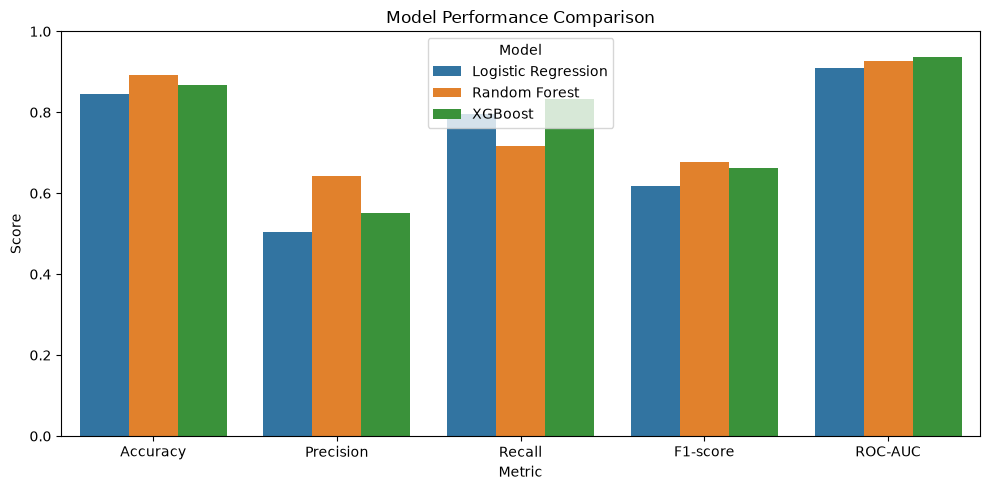

In [14]:
results_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))
sns.barplot(data=results_melted, x="Metric", y="Score", hue="Model")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "model_performance_comparison.png", dpi=300)
plt.show()

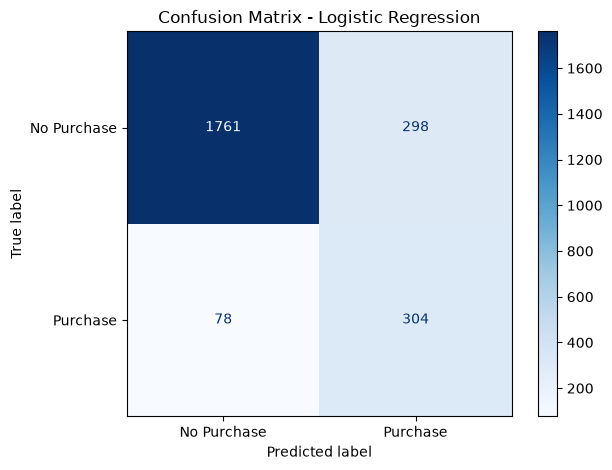

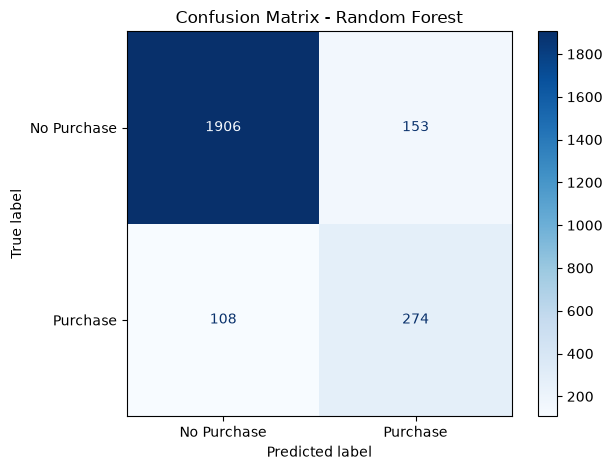

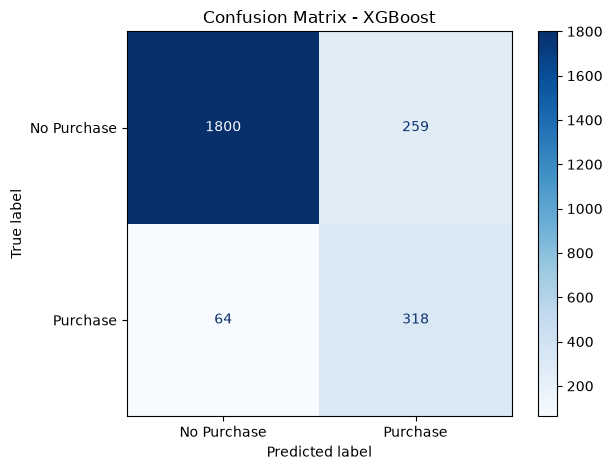

In [15]:
for model_name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Purchase", "Purchase"]
    )
    
    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / f"confusion_matrix_{model_name.lower().replace(' ', '_')}.png", dpi=300)
    plt.show()

In [16]:
best_model_name = results_df.sort_values(by="ROC-AUC", ascending=False).iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model selected:", best_model_name)

Best model selected: XGBoost


We select the best model based on ROC-AUC.

Why ROC-AUC?

Because we care about ranking customers by purchase likelihood, not only predicting 0 or 1.

For revenue optimization, probability ranking is very useful.

In [17]:
# Use Random Forest for feature importance
rf_model = trained_models["Random Forest"]

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
feature_importances = rf_model.named_steps["classifier"].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
}).sort_values(by="Importance", ascending=False)

feature_importance_df.head(15)

,Feature,Importance
8,num__PageValues,0.327961
7,num__ExitRates,0.094638
5,num__ProductRelated_Duration,0.080757
4,num__ProductRelated,0.065321
6,num__BounceRates,0.052290
1,num__Administrative_Duration,0.049320
0,num__Administrative,0.040682
17,cat__Month_Nov,0.024993
3,num__Informational_Duration,0.021452
2,num__Informational,0.015470


In [18]:
feature_importance_df["Feature"] = (
    feature_importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

feature_importance_df.head(15)

,Feature,Importance
8,PageValues,0.327961
7,ExitRates,0.094638
5,ProductRelated_Duration,0.080757
4,ProductRelated,0.065321
6,BounceRates,0.052290
1,Administrative_Duration,0.049320
0,Administrative,0.040682
17,Month_Nov,0.024993
3,Informational_Duration,0.021452
2,Informational,0.015470


In [19]:
feature_importance_df.to_csv(MODEL_RESULTS_PATH / "feature_importance_random_forest.csv", index=False)
feature_importance_df.head(15).to_csv(SLIDE_ASSETS_PATH / "top_feature_importance.csv", index=False)

print("Feature importance files saved successfully.")

Feature importance files saved successfully.


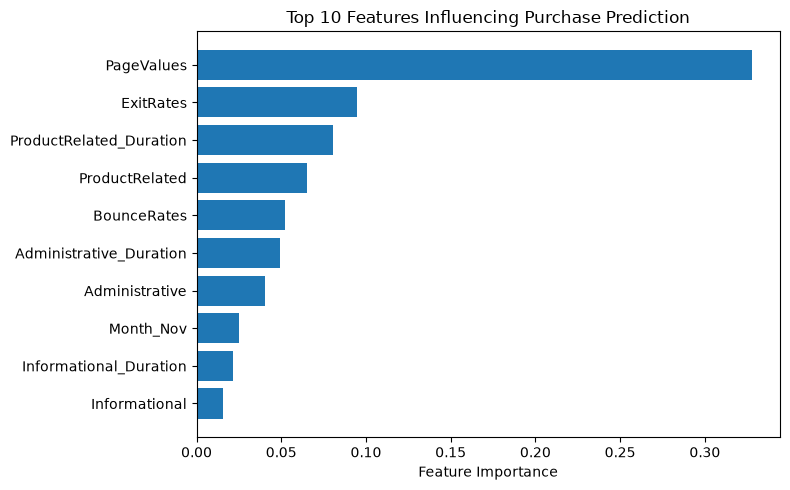

In [20]:
top_features = feature_importance_df.head(10).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Features Influencing Purchase Prediction")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "top_10_feature_importance.png", dpi=300)
plt.show()

In [22]:
# Feature importance from XGBoost
xgb_model = trained_models["XGBoost"]

feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()
feature_importances = xgb_model.named_steps["classifier"].feature_importances_

xgb_feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
}).sort_values(by="Importance", ascending=False)

xgb_feature_importance_df["Feature"] = (
    xgb_feature_importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

xgb_feature_importance_df.head(15)

,Feature,Importance
8,PageValues,0.206639
17,Month_Nov,0.078774
16,Month_May,0.052105
15,Month_Mar,0.047960
7,ExitRates,0.020010
22,VisitorType_Returning_Visitor,0.018842
13,Month_Jul,0.016774
5,ProductRelated_Duration,0.016645
19,Month_Sep,0.016548
6,BounceRates,0.016196


In [23]:
xgb_feature_importance_df.to_csv(
    MODEL_RESULTS_PATH / "feature_importance_xgboost.csv",
    index=False
)

xgb_feature_importance_df.head(15).to_csv(
    SLIDE_ASSETS_PATH / "top_feature_importance_xgboost.csv",
    index=False
)

print("XGBoost feature importance saved successfully.")

XGBoost feature importance saved successfully.


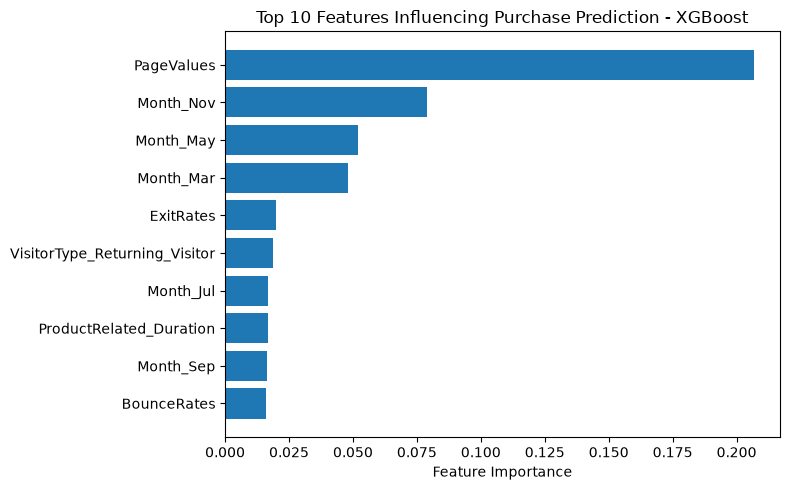

In [24]:
top_xgb_features = xgb_feature_importance_df.head(10).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(top_xgb_features["Feature"], top_xgb_features["Importance"])
plt.title("Top 10 Features Influencing Purchase Prediction - XGBoost")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "top_10_feature_importance_xgboost.png", dpi=300)
plt.show()

In [25]:
# Generate purchase probabilities for test data
test_output = X_test.copy()
test_output["actual_revenue"] = y_test.values
test_output["purchase_probability"] = best_model.predict_proba(X_test)[:, 1]

test_output.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,actual_revenue,purchase_probability
11640,0,0.000000,0,0.0,12,482.500000,0.02,0.040000,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,False,0,0.139193
6936,2,287.200000,0,0.0,16,473.283333,0.00,0.002222,0.0,0.0,Oct,2,2,1,2,New_Visitor,True,0,0.134234
7194,2,187.900000,4,100.1,29,2107.033333,0.00,0.024242,0.0,0.0,Oct,1,1,3,1,Returning_Visitor,False,0,0.139599
11263,7,280.266667,0,0.0,11,329.683333,0.00,0.023077,0.0,0.0,Dec,2,2,7,2,Returning_Visitor,False,0,0.190155
4728,0,0.000000,0,0.0,5,0.000000,0.20,0.200000,0.0,0.0,May,3,2,5,6,Returning_Visitor,False,0,0.000447


In [27]:
# Convert purchase probability into customer intent segments
def assign_intent_segment(probability):
    if probability >= 0.75:
        return "High Intent"
    elif probability >= 0.40:
        return "Medium Intent"
    else:
        return "Low Intent"

test_output["intent_segment"] = test_output["purchase_probability"].apply(assign_intent_segment)

test_output[[
    "purchase_probability",
    "intent_segment",
    "actual_revenue"
]].head(10)

,purchase_probability,intent_segment,actual_revenue
11640,0.139193,Low Intent,0
6936,0.134234,Low Intent,0
7194,0.139599,Low Intent,0
11263,0.190155,Low Intent,0
4728,0.000447,Low Intent,0
9878,0.915141,High Intent,0
8101,0.029458,Low Intent,0
6642,0.212766,Low Intent,0
10215,0.350532,Low Intent,0
10224,0.036681,Low Intent,0


In [28]:
def recommend_marketing_action(segment):
    if segment == "High Intent":
        return "Send checkout reminder or limited-time offer"
    elif segment == "Medium Intent":
        return "Send educational content about Nattoguard benefits"
    else:
        return "Retarget with awareness ad or product education"

test_output["recommended_action"] = test_output["intent_segment"].apply(recommend_marketing_action)

test_output[[
    "purchase_probability",
    "intent_segment",
    "recommended_action"
]].head(10)

,purchase_probability,intent_segment,recommended_action
11640,0.139193,Low Intent,Retarget with awareness ad or product education
6936,0.134234,Low Intent,Retarget with awareness ad or product education
7194,0.139599,Low Intent,Retarget with awareness ad or product education
11263,0.190155,Low Intent,Retarget with awareness ad or product education
4728,0.000447,Low Intent,Retarget with awareness ad or product education
9878,0.915141,High Intent,Send checkout reminder or limited-time offer
8101,0.029458,Low Intent,Retarget with awareness ad or product education
6642,0.212766,Low Intent,Retarget with awareness ad or product education
10215,0.350532,Low Intent,Retarget with awareness ad or product education
10224,0.036681,Low Intent,Retarget with awareness ad or product education


In [33]:
chatbot_ready_output = test_output[[
    "purchase_probability",
    "intent_segment",
    "recommended_action",
    "actual_revenue"
]].copy()

# Keep original row index as session_id so it can be merged later
chatbot_ready_output.insert(0, "session_id", chatbot_ready_output.index)

chatbot_ready_output.to_csv(
    CHATBOT_INPUTS_PATH / "customer_intent_recommendations.csv",
    index=False
)

chatbot_ready_output.head()

,session_id,purchase_probability,intent_segment,recommended_action,actual_revenue
11640,11640,0.139193,Low Intent,Retarget with awareness ad or product education,0
6936,6936,0.134234,Low Intent,Retarget with awareness ad or product education,0
7194,7194,0.139599,Low Intent,Retarget with awareness ad or product education,0
11263,11263,0.190155,Low Intent,Retarget with awareness ad or product education,0
4728,4728,0.000447,Low Intent,Retarget with awareness ad or product education,0


In [30]:
intent_distribution = test_output["intent_segment"].value_counts().reset_index()
intent_distribution.columns = ["Intent Segment", "Count"]

intent_distribution

,Intent Segment,Count
0,Low Intent,1773
1,High Intent,386
2,Medium Intent,282


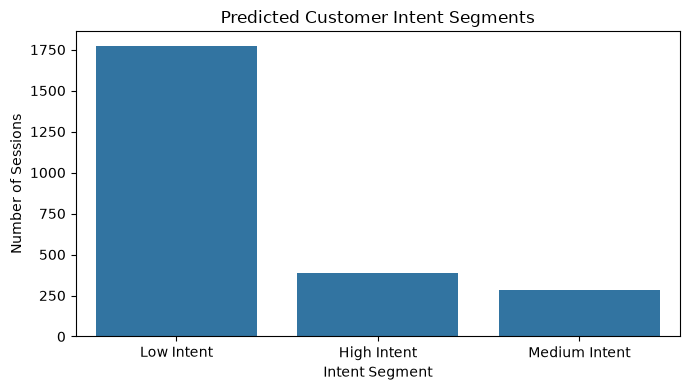

In [31]:
plt.figure(figsize=(7, 4))
sns.barplot(data=intent_distribution, x="Intent Segment", y="Count")
plt.title("Predicted Customer Intent Segments")
plt.xlabel("Intent Segment")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "predicted_customer_intent_segments.png", dpi=300)
plt.show()

In [32]:
intent_distribution.to_csv(SLIDE_ASSETS_PATH / "predicted_customer_intent_segments.csv", index=False)

print("Intent segment distribution saved successfully.")

Intent segment distribution saved successfully.


## Conversion Prediction Conclusion

In this notebook, machine learning models were trained to predict customer purchase behavior using session-level e-commerce data.

Logistic Regression was used as a baseline model because it is simple, interpretable, and suitable for binary classification. Random Forest was used as an advanced model because it can capture more complex customer behavior patterns and provide feature importance.

The model output was converted into purchase probability scores and customer intent segments. These segments were then mapped to recommended marketing actions.

This creates a direct connection between machine learning outputs and business decision-making. The saved customer intent recommendations will later be used for chatbot demo.